Dataset shape: (920, 14)
Data types:
age         float64
sex         float64
cp          float64
trestbps        str
chol            str
fbs             str
restecg         str
thalach         str
exang           str
oldpeak         str
slope           str
ca              str
thal            str
target        int64
dtype: object
Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
basic statistics:
              age         sex          cp      target
count  920.000000  920.000000  920.000000  920.000000
mean    53.510870    0.789130    3.250000    0.995652
std      9.424685    0.408148    0.930969    1.142693
min     28.000000    0.000000    1.000000    0.000000
25%     47.000000    1.000000    3.000000    0.000000
50%     54.000000    1.000000    4.000000    1.000000
75%     60.000000    1.000000    4.000000    2.0

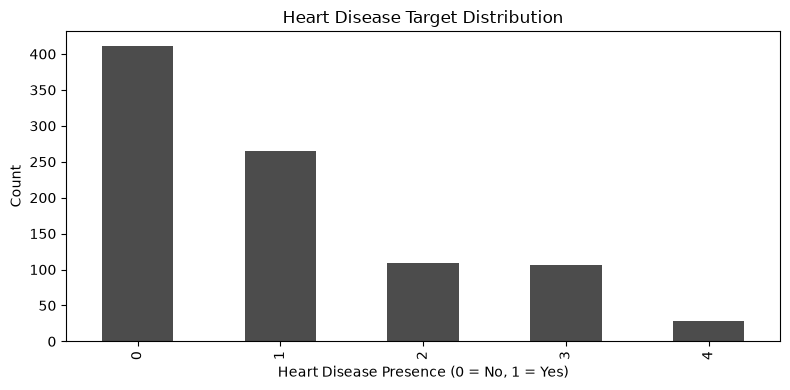

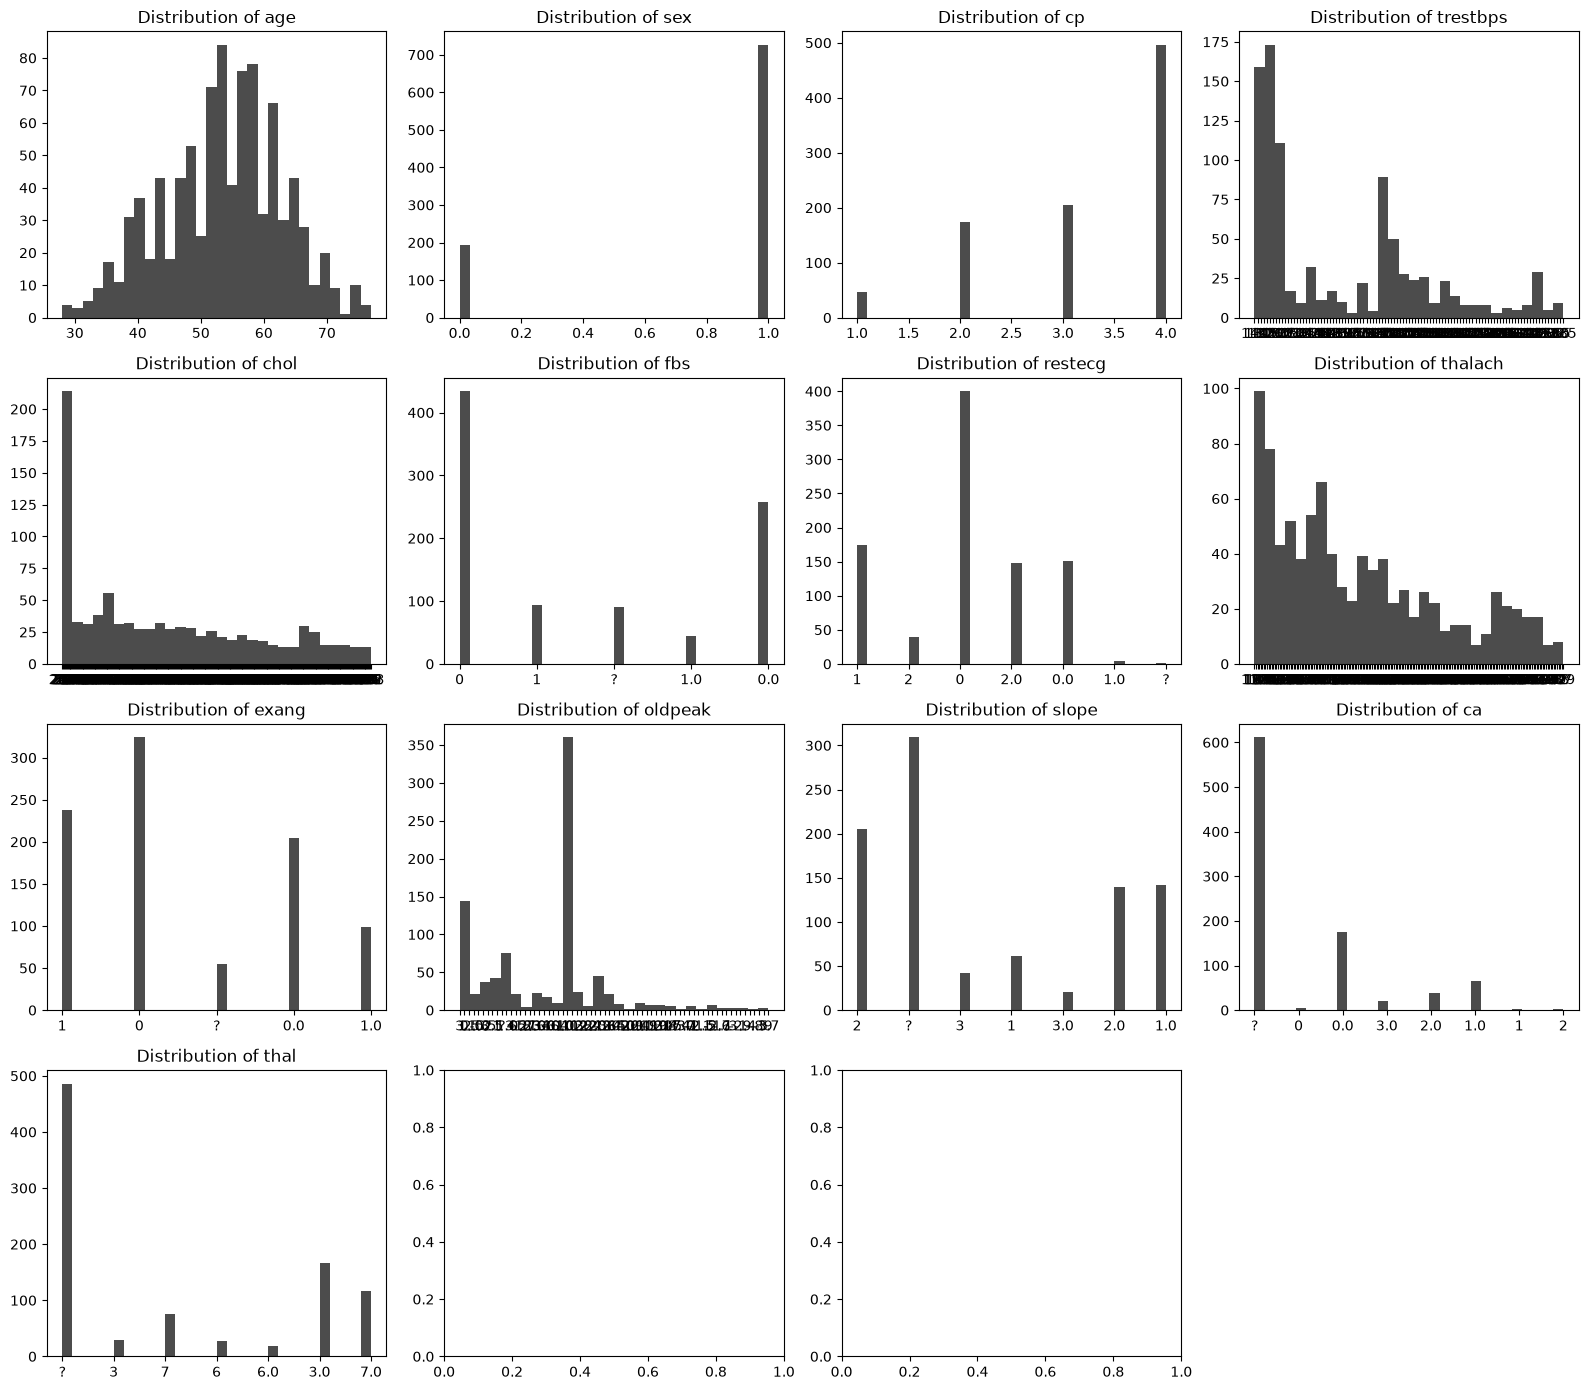

ValueError: could not convert string to float: '?'

<Figure size 1200x1000 with 0 Axes>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

data_path =  "../data/raw/heart.csv"
df = pd.read_csv(data_path,header=0)

# Data overview
print(f"Dataset shape: {df.shape}") 
print(f"Data types:\n{df.dtypes}")
print(f"Missing values:\n{df.isnull().sum()}")
print(f"basic statistics:\n{df.describe()}")

#Target variable distribution

plt.figure(figsize=(8,4))
df['target'].value_counts().plot(kind='bar', color='black', alpha=0.7)
plt.title('Heart Disease Target Distribution')
plt.xlabel('Heart Disease Presence (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../data/processed/target_distribution.png')
plt.show()

# Feature distribution for numerical features

flg, axes = plt.subplots(nrows=4, ncols=4, figsize=(16, 14))
axes=axes.ravel()
for idx, col in enumerate(df.columns[:-1]):  # Exclude target variable
    axes[idx].hist(df[col], bins=30, color='black', alpha=0.7)
    axes[idx].set_title(f'Distribution of {col}')
axes[-1].remove()  # Remove the last empty subplot
plt.tight_layout()
plt.savefig('../data/processed/feature_distributions.png')
plt.show()

# Correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('../data/processed/correlation_heatmap.png')
plt.show()


# Missing value analysis
sns.heatmap(df.isnull(), cbar=True , yticklabels=False, cmap='viridis')
missing_values = df.isnull().sum()
plt.title('Missing Values Heatmap')
plt.tight_layout()
plt.savefig('../data/processed/missing_values.png')
plt.show()





